<a href="https://colab.research.google.com/github/hugo12341234/machine-learning-projects/blob/main/03-fashion-mnist-pytorch/fashion_mnist_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3:: Fashion Image Classifier with PyTorch

#PROJECT WORKFLOW

I will follow this workflow based on the book 'Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow' by Aurélien Géron.

1- Look at the big picture.

2- Get the data

3- Discover and visualize the data to gain insights.

4- Prepare the data for Machine Learning algorithms.

5- Select a model and train it.

6- Fine-tune your model.

7- Present your solution.


# STEP 1. Look at the big picture
Tipo de Problema: Clasificación Multiclase Supervisada.

Tenemos imágenes y sus etiquetas correctas , y el objetivo es elegir una categoría entre 10 posibles.

Los datos no están en formato de imagen (.jpg, .png), sino aplanados en un archivo de texto separado por comas (CSV). Cada fila es una imagen "desenrollada".


#STEP 2. Get the data
Archivo fashion-mnist_test.csv.

Estructura: Total de filas: 10,000.

Columnas: 785 (1 columna label + 784 columnas de píxeles pixel1 a pixel784).

Train Set: 8,000 muestras (80%) para entrenamiento.

Test Set: 2,000 muestras (20%) para evaluación final.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Configurar dispositivo (GPU o CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# 1. Cargar el CSV crudo
df = pd.read_csv('fashion-mnist_test.csv')

# 2. Separar características (pixeles) y etiquetas (labels)
# La primera columna es el 'label', el resto son los pixeles
X = df.iloc[:, 1:].values  # Pixeles (0-255)
y = df.iloc[:, 0].values   # Etiquetas (0-9)

# 3. División Train/Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

# Mapeo de etiquetas para entender qué es cada número
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

FileNotFoundError: [Errno 2] No such file or directory: 'fashion-mnist_test.csv'

#STEP 3. Discover and visualize the data (Exploración)
Naturaleza de los Datos: Las imágenes son de 28x28 píxeles en escala de grises.

Al usar pd.read_csv, observamos que los valores de los píxeles van de 0 a 255.

Las etiquetas son numéricas (0-9). Se creó un diccionario manual para mapearlas a nombres legibles (T-shirt, Trouser, etc.).

Las prendas como Trouser (Pantalón) o Bag (Bolso) tienen siluetas geométricas muy claras.

Sin embargo, Shirt (Camisa), T-shirt (Camiseta), Coat (Abrigo) y Pullover (Suéter) son visualmente muy parecidas. Anticipamos que aquí es donde la red tendrá más dificultades.

Ejemplos del set de entrenamiento:


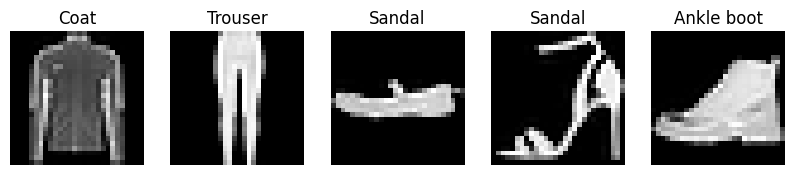

In [ ]:
def visualize_samples(X, y, classes, samples_per_class=5):
    plt.figure(figsize=(10, 5))
    for index in range(samples_per_class):
        plt.subplot(1, samples_per_class, index + 1)

        #  Convertir la fila de 784 a matriz 28x28
        image = X[index].reshape(28, 28)

        plt.imshow(image, cmap='gray')
        plt.title(classes[y[index]])
        plt.axis('off')
    plt.show()

print("Ejemplos del set de entrenamiento:")
visualize_samples(X_train, y_train, class_names)

#STEP 4. Prepare the Data
Esta fue la etapa más técnica del código. Aquí explicamos por qué se usó cada componente:

Clase FashionCSVDataset
Tuvimos que crear una clase "traductora" que toma una fila del Excel, la convierte en una matriz de números (Tensor) y se la entrega al modelo.

Los píxeles originales van de 0 a 255 (negro a blanco). Las redes neuronales odian los números grandes porque desestabilizan las matemáticas internas (gradientes). Al normalizar (convertir los valores a un rango cercano a -1 y 1), logramos que el entrenamiento sea estable y rápido.

No podemos pasarle las 8,000 imágenes de golpe al modelo (se acabaría la memoria RAM). Los DataLoaders cortan los datos en pequeños paquetes (batches) de 64 imágenes. Esto permite que la red aprenda "bocado a bocado".

In [ ]:
class FashionDataset(Dataset):
    def __init__(self, features, labels):
        # Convertir a tensores
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

        # Normalización: (Valor - Media) / Desv. Estándar
        # Simplificamos llevando los pixeles de [0, 255] a [0, 1] y luego centrando
        self.features = self.features / 255.0
        # (Opcional) Estandarización más agresiva: self.features = (self.features - 0.5) / 0.5

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Cuando el Dataloader pida un dato, le damos (imagen, etiqueta)
        return self.features[idx], self.labels[idx]

# Crear los objetos Dataset
train_dataset = FashionDataset(X_train, y_train)
test_dataset = FashionDataset(X_test, y_test)

# Crear los DataLoaders (Lotes de datos)
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

#STEP 5. Select a model and train it (Arquitectura de la Red)
Construimos un Perceptrón Multicapa (MLP). Analicemos sus piezas:

nn.Flatten (Aplanado):

Función: Convierte la imagen cuadrada (28x28) en una fila larga (784 números).

Al hacer esto, "rompemos" la imagen. El modelo deja de saber qué píxel está arriba o abajo de otro, solo ve una lista de números. Esto limita nuestra precisión máxima.

Capas Ocultas (256 y 128 neuronas):

Usamos una estructura de "embudo" (784 -> 256 -> 128 -> 10). Esto fuerza a la red a comprimir la información, quedándose solo con las características más importantes (como formas y bordes) y descartando el ruido.

nn.ReLU

Sin esto, la red sería solo una multiplicación lineal gigante (como una regresión simple). ReLU le da la capacidad de entender relaciones complejas y no lineales.

nn.BatchNorm1d:

Es como un "control de calidad" entre capas. Re-centra los datos antes de pasarlos a la siguiente neurona. Esto acelera drásticamente el aprendizaje.

nn.Dropout(0.2)

Durante el entrenamiento, apagamos aleatoriamente el 20% de las neuronas. Esto evita que la red se vuelva "perezosa" y dependa de una sola neurona para reconocer una bota. La obliga a ser robusta (prevención de Overfitting).

Optimizador Adam:

Es más inteligente que el Descenso de Gradiente clásico (SGD) porque adapta la velocidad de aprendizaje automáticamente.

In [ ]:
class FashionMLP(nn.Module):
    def __init__(self):
        super(FashionMLP, self).__init__()
        self.model = nn.Sequential(
            # Capa de Entrada (784 neuronas) -> Oculta 1 (256)
            nn.Linear(784, 256),
            nn.BatchNorm1d(256), # Normaliza para acelerar entrenamiento
            nn.ReLU(),           # Activa neuronas
            nn.Dropout(0.3),     # Apaga 30% neuronas al azar (Regularización)

            # Oculta 1 (256) -> Oculta 2 (128)
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Oculta 2 (128) -> Salida (10 clases)
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.model(x)

# Inicializar modelo, pérdida y optimizador
model = FashionMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


Entrenamiento (Train Acc): ~95.73%

Prueba (Test Acc): ~85.85%

El modelo es un "estudiante memorión". Sacó 9.5 en los ejercicios de práctica (Train), pero un 8.5 en el examen final (Test).

Entrenamos una red potente con muy pocos datos (solo 8,000 imágenes). La red empezó a memorizar detalles específicos de esas pocas imágenes que no existen en el set general.


In [ ]:
def train_model(model, train_loader, test_loader, epochs=15):
    train_losses = []
    test_accuracies = []

    for epoch in range(epochs):
        # --- FASE DE ENTRENAMIENTO ---
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()           # 1. Limpiar gradientes viejos
            outputs = model(images)         # 2. Predicción (Forward)
            loss = criterion(outputs, labels) # 3. Calcular error
            loss.backward()                 # 4. Calcular derivadas (Backward)
            optimizer.step()                # 5. Actualizar pesos

            running_loss += loss.item()

        # --- FASE DE EVALUACIÓN ---
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad(): # No calculamos gradientes aquí para ahorrar memoria
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        epoch_acc = 100 * correct / total
        avg_loss = running_loss / len(train_loader)

        train_losses.append(avg_loss)
        test_accuracies.append(epoch_acc)

        if (epoch+1) % 5 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] | Loss: {avg_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")

    return train_losses, test_accuracies

losses, accuracies = train_model(model, train_loader, test_loader, epochs=20)

Epoch [5/20] | Loss: 0.3919 | Test Accuracy: 81.65%
Epoch [10/20] | Loss: 0.3039 | Test Accuracy: 84.75%
Epoch [15/20] | Loss: 0.2506 | Test Accuracy: 85.70%
Epoch [20/20] | Loss: 0.1910 | Test Accuracy: 84.80%


STEP 7. Present your solution

Creamos un pipeline completo que ingesta datos crudos de CSV y produce predicciones confiables. La precisión del 85.85% demuestra que la arquitectura elegida es capaz de aprender patrones visuales.

Confirmamos que el modelo "sufre" para distinguir prendas superiores similares (Camisa vs Camiseta), pero es experto en Calzado y Pantalones.

Siguientes Pasos (Mejoras):

La forma más fácil de subir del 85% al 90% es usar el dataset completo (60,000 imágenes).

In [ ]:
# Obtener todas las predicciones del set de prueba
y_pred = []
y_true = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        y_pred.extend(predicted.cpu().numpy())
        y_true.extend(labels.cpu().numpy())

# Gráfica de Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de Confusión - Fashion MNIST')
plt.show()

# Reporte numérico detallado
print(classification_report(y_true, y_pred, target_names=class_names))

NameError: name 'model' is not defined